# Week 6: Common regression methods

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data exported from Week 5.
regression_df = pd.read_csv(
    "regression_data.csv",
    parse_dates=["hour_local"]
)

# All remaining columns are predictors.
core_features = regression_df.columns.drop(
    ["hour_local", "avg_departure_delay"]
).tolist()

print(f"Loaded {len(regression_df):,} rows and {len(core_features)} predictors.")

Loaded 28,499 rows and 23 predictors.


## Tutorial

In this tutorial, we'll use the ORD flight and weather data from Week 5 to build five machine learning models:

1. Linear Regression
2. Ridge Regression
3. LASSO Regression
4. Random Forest Regression
5. Gradient Boosting Regression

We'll use scikit-learn (sklearn) for all five models. The goal is to understand how the models work, how to train them, and how to evaluate their predictions.

By the end, you should be able to experiment with these models independently.

Before starting: Run the setup cell above to load `regression_df` and `core_features` from `regression_data.csv`.

## 1. Preparing our data

### What are we predicting?

Our goal is to predict `avg_departure_delay`, the average departure delay, in minutes, for a group of flights.

We call this our target variable, or y.

Everything we use to make that prediction is called a feature, or X.

For example, our features include:

- `scheduled_flights`: Number of flights scheduled in an hour.
- `temperature_c`: Temperature in Celsius.
- `wind_max_ms`: Maximum wind speed.
- `visibility_min_m`: Minimum visibility.
- `hour_sin` and `hour_cos`: Variables representing the time of day.

Let's select the data we prepared last week.

In [3]:
# Sort our data by date and time
data = regression_df.sort_values("hour_local")

# X contains the features we use to make predictions
X = data[core_features]

# y contains the variable we want to predict
y = data["avg_departure_delay"]

print(X.shape)
print(y.shape)

(28499, 23)
(28499,)


### Training, validation, and testing data: 70/15/15

We don't want to evaluate our models using the same data they learned from.

Why? Because a model might memorize patterns in its training data without learning relationships that generalize to new observations. This is called overfitting.

We'll divide our data into three groups in chronological order:

- Training data (70%): Used to teach the models.
- Validation data (15%): Used to compare models and choose hyperparameters.
- Testing data (15%): Reserved for the final evaluation of the selected model.

Train on the earliest observations, validate on the next observations, and test on the latest observations. Whole-row rounding can make the percentages differ slightly.

In [4]:
# Sort data chronologically
data = regression_df.sort_values("hour_local")

X = data[core_features]
y = data["avg_departure_delay"]

# Define split points
train_end = int(len(X) * 0.70)
val_end = int(len(X) * 0.85)

# Training data
X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

# Validation data
X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

# Testing data
X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

print("Training rows (70%):", len(X_train))
print("Validation rows (15%):", len(X_val))
print("Testing rows (15%):", len(X_test))

Training rows (70%): 19949
Validation rows (15%): 4275
Testing rows (15%): 4275


We'll use the same training and validation datasets for every model. This allows us to compare them fairly. Keep the testing data unused until the final evaluation.

### How do we evaluate a model?

We'll use two metrics:

Mean Absolute Error (MAE) measures how far our predictions are from the actual values, on average.

For example, an MAE of 5 means our predictions are off by an average of 5 minutes.

R-squared (R²) measures how well the model performs compared with predicting a constant value.

- 1.0: Perfect predictions.
- 0.0: No better than predicting the evaluated set's average.
- Negative: Worse than predicting the evaluated set's average.

Higher R² and lower MAE are better. R² is not the percentage of predictions that are correct.

In [5]:
from sklearn.metrics import mean_absolute_error, r2_score

## 2. Linear Regression

### How does it work?

Linear regression attempts to find the straight-line relationship between our features and the target variable.

With one feature, the equation is:
$$
\hat y = b_0 + b_1x
$$

- x represents our feature.
- b0 represents the intercept.
- b1 represents the coefficient (slope).
- ŷ represents our prediction.

When we have multiple features, the model simply adds more coefficients.

Linear regression finds the coefficients that minimize the sum of squared differences between the predictions and actual values.

### Training the model

Scikit-learn makes this surprisingly simple!

In [6]:
from sklearn.linear_model import LinearRegression

# Create the model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

# Make validation predictions
linear_pred = linear_model.predict(X_val)

Notice the three steps:

1. `LinearRegression()` creates the model.
2. `.fit()` teaches the model using the training data.
3. `.predict()` uses the trained model to make predictions.

These three steps will be almost identical for every model we study.

### Evaluating on validation data

In [8]:
print("Validation MAE:", mean_absolute_error(y_val, linear_pred))
print("Validation R²:", r2_score(y_val, linear_pred))

Validation MAE: 11.915905410129259
Validation R²: 0.07386139009455606


We can also examine the coefficients that the model learned.

In [7]:
# Display the coefficient for each feature
coefficients = pd.Series(linear_model.coef_, index=X.columns)
print(coefficients)

scheduled_flights            0.008884
airlines                     0.201009
origins                     -0.059055
avg_distance                -0.023804
avg_scheduled_flight_time    0.223122
temperature_c                0.045782
wind_max_ms                  0.596227
visibility_min_m            -0.000732
dew_point_spread_c          -0.715876
freezing_deficit_c           1.556944
high_wind                    7.653676
low_visibility              -2.409195
traffic_low_visibility       0.384982
hour_sin                    -5.592248
hour_cos                     4.174076
season_sin                   1.285766
season_cos                  -7.965121
dow_tue                     -2.864467
dow_wed                     -1.654199
dow_thu                     -0.380066
dow_fri                      1.558589
dow_sat                      0.355269
dow_sun                      1.628359
dtype: float64


Each coefficient describes the predicted change in average departure delay associated with a one-unit increase in that feature, holding the others constant.

For instance, a coefficient of 2 for `scheduled_flights` would mean that an additional scheduled flight is associated with 2 more minutes of predicted average delay, assuming all other features remain constant.

Remember: correlation and regression coefficients do not establish causation. Also, because features use different units, raw coefficient sizes should not be used to rank their importance.

## 3. Ridge Regression

### How does it work?

Ridge regression is extremely similar to linear regression.

However, Ridge adds a penalty when the model assigns large values to its coefficients.

Why is this useful?

Imagine two features are highly correlated, such as temperature and dew point. Ordinary linear regression can assign unstable coefficients when features contain overlapping information.

Ridge discourages large coefficients, which can make the model more stable and reduce overfitting.

The strength of the penalty is controlled by a parameter called alpha (alpha).

- Small alpha: Behaves more like ordinary linear regression.
- Large alpha: Shrinks the coefficients more aggressively.

### Scaling our features

Before using Ridge, we should scale our features.

For example, temperature might range from -20 to 40, while visibility might range from 0 to 10,000.

Because Ridge penalizes coefficients, the different scales of our features can affect the penalty.

`StandardScaler()` puts features on a comparable scale by subtracting their training-set means and dividing by their training-set standard deviations.

We'll use `make_pipeline()` to combine scaling and regression automatically.

In [9]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Create model with scaling
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

# Train model
ridge_model.fit(X_train, y_train)

# Make validation predictions
ridge_pred = ridge_model.predict(X_val)

A pipeline applies the scaler before passing the data into the regression model. Importantly, it learns the scaling values from the training data, not the validation or testing data.

### Evaluating on validation data

In [10]:
print("Validation MAE:", mean_absolute_error(y_val, ridge_pred))
print("Validation R²:", r2_score(y_val, ridge_pred))

Validation MAE: 11.914940751707118
Validation R²: 0.07386878949820586


Try changing `alpha=1.0` to `alpha=10.0` or `alpha=100.0`.

Does the model perform better or worse?

## 4. LASSO Regression

### How does it work?

LASSO stands for Least Absolute Shrinkage and Selection Operator.

Like Ridge, LASSO penalizes large coefficients.

However, there is one important difference:

- Ridge: Shrinks coefficients toward zero, but generally keeps all features.
- LASSO: Can shrink coefficients all the way to zero, effectively removing some features.

This makes LASSO particularly useful for feature selection.

Imagine we have 20 features, but only 8 are especially useful for predicting delays. LASSO might assign coefficients of zero to some of the less useful features.

Like Ridge, LASSO uses alpha to control the penalty strength.

### Training the model

In [11]:
from sklearn.linear_model import Lasso

# Create model with scaling
lasso_model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=0.1, max_iter=10000)
)

# Train model
lasso_model.fit(X_train, y_train)

# Make validation predictions
lasso_pred = lasso_model.predict(X_val)

We added `max_iter=10000` to allow the algorithm more iterations to converge.

### Evaluating on validation data

In [12]:
print("Validation MAE:", mean_absolute_error(y_val, lasso_pred))
print("Validation R²:", r2_score(y_val, lasso_pred))

Validation MAE: 11.802576836203224
Validation R²: 0.07483618441983853


### Which features did LASSO remove?

One of LASSO's biggest advantages is that it can eliminate features by setting their coefficients to zero.

Let's inspect the coefficients.

In [13]:
# Access the LASSO model inside our pipeline
lasso = lasso_model.named_steps["lasso"]

# Display coefficients
coefficients = pd.Series(lasso.coef_, index=X.columns)
print(coefficients)

scheduled_flights           -0.000000
airlines                     0.211050
origins                     -1.030292
avg_distance                -0.796968
avg_scheduled_flight_time    0.000000
temperature_c                0.000000
wind_max_ms                  1.270436
visibility_min_m            -2.444189
dew_point_spread_c          -3.162120
freezing_deficit_c           3.954403
high_wind                    0.922553
low_visibility               0.000000
traffic_low_visibility       1.274350
hour_sin                    -4.395906
hour_cos                     2.597455
season_sin                   0.761669
season_cos                  -5.774424
dow_tue                     -0.897317
dow_wed                     -0.476706
dow_thu                     -0.039401
dow_fri                      0.464128
dow_sat                      0.035132
dow_sun                      0.487627
dtype: float64


Any feature with a coefficient of zero has been eliminated from the model.

Try increasing alpha to 1.0.

Do more features receive coefficients of zero?

## 5. Random Forest Regression

### How does it work?

Random forests work very differently from linear regression.

Instead of fitting an equation, a random forest creates a collection of decision trees.

A decision tree makes predictions by repeatedly dividing the data into groups based on feature values.

For example, a simplified tree might ask:
Illustrative decision tree with hypothetical delay predictions, not results from our dataset.
A random forest builds many different decision trees, each trained on a random sample of the observations while considering random subsets of features at each split.

For regression, it averages the trees' predictions to produce a final prediction.

Random forests are especially useful because they can capture nonlinear relationships that ordinary linear regression might miss.

### Training the model

In [15]:
from sklearn.ensemble import RandomForestRegressor

# Create model
forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=8,
    random_state=42
)

# Train model
forest_model.fit(X_train, y_train)

# Make validation predictions
forest_pred = forest_model.predict(X_val)

We introduced three parameters:

- `n_estimators=100`: Build 100 decision trees.
- `max_depth=8`: Limit how deep each tree can grow.
- `random_state=42`: Make the random process reproducible.

Unlike Ridge and LASSO, random forests don't require feature scaling.

### Evaluating on validation data

In [16]:
print("Validation MAE:", mean_absolute_error(y_val, forest_pred))
print("Validation R²:", r2_score(y_val, forest_pred))

Validation MAE: 11.84435414071119
Validation R²: 0.08107398113878894


### Which features are important?

Random forests can estimate the relative importance of each feature in their decisions.

In [15]:
# Get feature importances
importance = pd.Series(
    forest_model.feature_importances_,
    index=X.columns
)

# Display the 10 most important
print(importance.sort_values(ascending=False).head(10))

dew_point_spread_c           0.125711
season_cos                   0.109631
temperature_c                0.107602
season_sin                   0.098511
wind_max_ms                  0.081311
hour_sin                     0.077626
visibility_min_m             0.061744
hour_cos                     0.044707
avg_scheduled_flight_time    0.042651
avg_distance                 0.041696
dtype: float64


Higher values indicate that a feature contributed more to reducing prediction error inside the forest's trees.

These are model-specific importance scores, not measures of causality.

## 6. Gradient Boosting Regression

### How does it work?

Gradient boosting also uses decision trees, but combines them differently from random forests.

Random forests build many trees independently and average their predictions.

Gradient boosting builds trees sequentially, with each new tree trying to improve the predictions produced by the previous trees.

Imagine predicting flight delays:

1. Our initial prediction is 10 minutes for every observation.
2. Our first tree tries to explain where that prediction is wrong.
3. Another tree learns to correct some of the remaining mistakes.
4. Additional trees continue improving the combined predictions.

The actual algorithm uses a mathematical process called gradient descent to determine how each new tree should improve the model.

### Training the model

In [19]:
from sklearn.ensemble import GradientBoostingRegressor

# Create model
boost_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train model
boost_model.fit(X_train, y_train)

# Make validation predictions
boost_pred = boost_model.predict(X_val)

Three important parameters:

- `n_estimators=100`: Number of boosting stages (trees).
- `learning_rate=0.1`: Controls how strongly each new tree contributes to the prediction.
- `max_depth=3`: Controls how complicated each tree can become.

A smaller learning rate often requires more trees to learn effectively.

### Evaluating on validation data

In [20]:
print("Validation MAE:", mean_absolute_error(y_val, boost_pred))
print("Validation R²:", r2_score(y_val, boost_pred))

Validation MAE: 11.108484272229104
Validation R²: 0.10929684687266616


We can also inspect feature importance.

In [21]:
importance = pd.Series(
    boost_model.feature_importances_,
    index=X.columns
)
print(importance.sort_values(ascending=False).head(10))

season_cos                0.179686
season_sin                0.118137
hour_sin                  0.108195
visibility_min_m          0.104837
temperature_c             0.097125
hour_cos                  0.078849
dew_point_spread_c        0.074104
wind_max_ms               0.072642
freezing_deficit_c        0.056002
traffic_low_visibility    0.035274
dtype: float64


## 7. Comparing our models

Now that we've trained all five models, let's compare their performance using the same validation data.

Instead of looking at five separate outputs, we'll make a simple table.

In [22]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge",
        "LASSO",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mean_absolute_error(y_val, linear_pred),
        mean_absolute_error(y_val, ridge_pred),
        mean_absolute_error(y_val, lasso_pred),
        mean_absolute_error(y_val, forest_pred),
        mean_absolute_error(y_val, boost_pred)
    ],
    "R²": [
        r2_score(y_val, linear_pred),
        r2_score(y_val, ridge_pred),
        r2_score(y_val, lasso_pred),
        r2_score(y_val, forest_pred),
        r2_score(y_val, boost_pred)
    ]
})

# Sort models from lowest to highest validation error
results.sort_values("MAE")

,Model,MAE,R²
4,Gradient Boosting,11.108484,0.109297
2,LASSO,11.802577,0.074836
3,Random Forest,11.844354,0.081074
1,Ridge,11.914941,0.073869
0,Linear Regression,11.915905,0.073861


### What should we look for?

First, identify the model with the lowest MAE.

This model makes the smallest average absolute prediction error on our validation data.

Next, examine R². Does the model with the lowest MAE also have the highest R²?

Not necessarily! These metrics evaluate performance differently.

Finally, compare the more complex models with ordinary linear regression.

If gradient boosting performs only slightly better than linear regression, the increased complexity might not be worthwhile.

### Visualizing our predictions

Let's compare actual validation delays with the predictions made by gradient boosting.

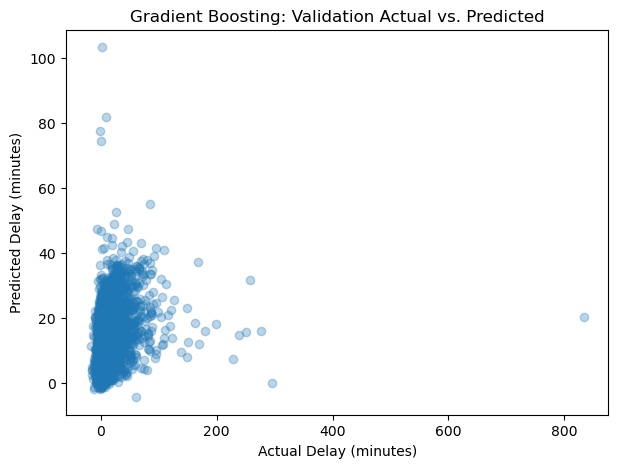

In [23]:
plt.figure(figsize=(7, 5))
plt.scatter(y_val, boost_pred, alpha=0.3)
plt.xlabel("Actual Delay (minutes)")
plt.ylabel("Predicted Delay (minutes)")
plt.title("Gradient Boosting: Validation Actual vs. Predicted")
plt.show()

In an ideal model, predicted delays would closely match actual delays.

If predictions consistently underestimate especially large delays, the model may be struggling to capture extreme events.

## 8. Experimenting with hyperparameters

So far, we've used a single set of parameters for each model.

But these settings aren't necessarily the best!

A hyperparameter is a setting we choose before training a model. For example, the number of trees in a random forest is a hyperparameter.

Let's experiment with a random forest using more trees.

In [26]:
# Try a larger forest
new_forest = RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    random_state=42
)
new_forest.fit(X_train, y_train)
new_pred = new_forest.predict(X_val)

print("Original validation MAE:", mean_absolute_error(y_val, forest_pred))
print("New validation MAE:", mean_absolute_error(y_val, new_pred))

Original validation MAE: 11.84435414071119
New validation MAE: 11.813142048949953


Did the model improve?

You can experiment with other values, too.

| Model | Parameter | What to experiment with |
| --- | --- | --- |
| Ridge | alpha | 0.1, 1, 10, 100 |
| LASSO | alpha | 0.01, 0.1, 1 |
| Random Forest | max_depth | 3, 5, 10, 20 |
| Gradient Boosting | learning_rate | 0.01, 0.05, 0.1 |

## Try GridSearchCV if you want!

For now, change just one parameter at a time to see what happens. Later, you can learn how to automate hyperparameter tuning using cross-validation.

Use validation performance to choose parameters. Keep the testing data untouched until those choices are finished; changing the model after inspecting test scores would make the final evaluation less independent.

## 9. Putting everything together

Here's a summary of the five models we've explored.

| Model | Main idea | Biggest strength |
| --- | --- | --- |
| Linear Regression | Finds a linear relationship between features and the target | Simple and interpretable |
| Ridge | Linear regression with coefficient penalties | Handles correlated features |
| LASSO | Linear regression that can eliminate features | Feature selection |
| Random Forest | Averages predictions from many decision trees | Captures nonlinear relationships |
| Gradient Boosting | Builds trees sequentially to improve predictions | Captures complex patterns |

All five models use the same basic structure in scikit-learn:

In [24]:
# 1. Create a model
model = LinearRegression()

# 2. Train the model
model.fit(X_train, y_train)

# 3. Make validation predictions
predictions = model.predict(X_val)

# 4. Evaluate on validation data
print(mean_absolute_error(y_val, predictions))

11.915905410129259


Once you understand these four steps, you've learned the foundation for working with many other machine learning models.

## 10. Independent practice

For your independent work this week, try answering these questions using the ORD validation data before the final test evaluation:

1. Which of the five models produces the lowest MAE? Which produces the highest R²?
2. How does increasing alpha affect the performance of Ridge and LASSO? How many features does LASSO eliminate?
3. Does increasing the number of trees in the random forest improve its predictions?
4. Which five features are most important to the random forest and gradient boosting models? Do the models agree?
5. Do your models tend to underestimate or overestimate the largest departure delays?

### Final evaluation on testing data

After completing model comparisons and parameter experiments, select the trained model with the lowest validation MAE, including the larger random forest from Section 8. Evaluate only that selected model on the final 15% of observations. Keep the chosen model fixed after viewing its test scores.

In [27]:
# Select a model using validation data only
models = {
    "Linear Regression": linear_model,
    "Ridge": ridge_model,
    "LASSO": lasso_model,
    "Random Forest": forest_model,
    "Gradient Boosting": boost_model,
    "Larger Random Forest": new_forest
}
validation_mae = pd.Series({
    name: mean_absolute_error(y_val, model.predict(X_val))
    for name, model in models.items()
})
best_name = validation_mae.idxmin()
best_model = models[best_name]

# Evaluate the selected model on the untouched testing data
test_pred = best_model.predict(X_test)
print("Selected model:", best_name)
print("Test MAE:", mean_absolute_error(y_test, test_pred))
print("Test R²:", r2_score(y_test, test_pred))

Selected model: Gradient Boosting
Test MAE: 14.944590704376317
Test R²: 0.10075353031309864


## For next week:
Using the data from week5.ipynb, run a series of regressions using each of the methods discussed. Try to play around with different sets of features and hyperparameters. At the bottom of your notebooks, jot down some interesting findings. Please have this done by Monday night so that I can review before our next meeting.